# UCS420 Lab Assignment 9 — NLP Text Preprocessing

In [22]:
ROLL_NO = 1024170226          # <-- your full roll number
NAME = "Gurnoor Singh Marok"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170226   Name: Gurnoor Singh Marok   Fingerprint: 163C0C91   Tickets: 13

Ticket_ID                                                                                 Ticket_Text
      T01                                  The e-mail is showing an error. I don't know what changed.
      T02                                                       I need Windows 11 by 5.30 p.m. today.
      T03                                                       Nothing works and nobody has replied.
      T04             Password is running slowly while uploading the file. Is there another solution?
      T05                                                       I tried again... still no response!!!
      T06          Matlab keeps disconnecting after resetting my password. I don't know what changed.
      T07            I cannot access the laptop when I use mobile hotspot. Is there another solution?
      T08                             The Python was working yesterday. It works on another c

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import re
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

from nltk import pos_tag, bigrams
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)

tickets = df["Ticket_Text"].tolist()
ticket_ids = df["Ticket_ID"].tolist()

# run process_ticket() on every ticket
processed = {tid: process_ticket(t) for tid, t in zip(ticket_ids, tickets)}

rows = []
for tid, p in processed.items():
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation": len(p["punct"]),
        "Stopwords": len(p["stops"]),
        "Unique Tokens": len(set(p["tokens"])),
        "Final Tokens": len(p["final"]),
    })

q1 = pd.DataFrame(rows)
q1.loc[len(q1)] = ["TOTAL"] + [q1[c].sum() for c in q1.columns[1:]]
display(q1)

# one selected ticket in detail (change to any Ticket_ID)
selected = FOCUS[0]
p = processed[selected]

print(f"\nSelected ticket {selected}: {tickets[ticket_ids.index(selected)]}\n")
print("Tokens      :", p["tokens"])
print("Punctuation :", p["punct"])
print("Stopwords   :", p["stops"])
print("Final tokens:", p["final"])

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,14,2,6,13,6
1,T02,1,9,1,2,9,6
2,T03,1,7,1,2,7,4
3,T04,2,14,2,5,13,7
4,T05,2,10,4,3,8,3
5,T06,2,15,2,5,14,8
6,T07,2,17,2,8,16,7
7,T08,2,12,2,4,11,6
8,T09,1,7,2,2,7,3
9,T10,2,16,2,4,15,10



Selected ticket T02: I need Windows 11 by 5.30 p.m. today.

Tokens      : ['i', 'need', 'windows', '11', 'by', '5.30', 'p.m.', 'today', '.']
Punctuation : ['.']
Stopwords   : ['i', 'by']
Final tokens: ['need', 'windows', '11', '5.30', 'p.m.', 'today']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* They come from `word_tokenize()`, which follows the Penn Treebank rules and splits a contraction into a stem plus a clitic (`can't` -> `ca` + `n't`, `won't` -> `wo` + `n't`, `isn't` -> `is` + `n't`, `Rao's` -> `rao` + `'s`). `process_ticket()` only removes punctuation and NLTK stopwords, and these fragments are in neither list, so they survive into the final tokens. Other odd tokens are pieces of emails/URLs that `word_tokenize()` cuts apart (`helpdesk@university.edu` -> `helpdesk`, `@`, `university.edu`), numbers and mixed alphanumeric strings (`0x80070005`, `2.0.1`, `lab-3`), and acronyms / product names (`lms`, `vpn`, `wifi`) that are not ordinary words. The cell below lists the ones that actually occur in this dataset.

In [6]:

all_final = sorted(set(w for p in processed.values() for w in p["final"]))
raw_lower = " ".join(tickets).lower()

fragments = [w for w in all_final if w == "n't" or w.startswith("'") or (w + "n't") in raw_lower]
non_alpha = [w for w in all_final if w not in fragments and not w.isalpha()]
unknown   = [w for w in all_final if w.isalpha() and w not in fragments and not wordnet.synsets(w)]

print("Contraction pieces left by word_tokenize:", fragments)
print("Numbers / mixed tokens :", non_alpha)
print("Not in WordNet (acronyms / domain terms):", unknown)

print("\nContractions in the raw tickets and how word_tokenize splits them:")
for c in sorted(set(re.findall(r"\b\w+'\w+", " ".join(tickets)))):
    print(f"  {c:12} -> {word_tokenize(c)}")


Contraction pieces left by word_tokenize: ['ca', "n't"]
Numbers / mixed tokens : ['11', '5.30', 'e-mail', 'p.m.', 'university.edu']
Not in WordNet (acronyms / domain terms): ['matlab']

Contractions in the raw tickets and how word_tokenize splits them:
  can't        -> ['ca', "n't"]
  don't        -> ['do', "n't"]


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# ---- patterns ----
# words longer than 5 letters (a contraction such as couldn't counts its letters: 7)
LONG_WORD = r"\b(?=(?:[A-Za-z]'?){6})[A-Za-z]+(?:'[A-Za-z]+)*\b"
# numbers: hex codes, thousands separators, decimals and versions stay whole
NUMBER    = r"\b0[xX][0-9A-Fa-f]+\b|(?<![\d.,])\d+(?:,\d{3})+(?:\.\d+)?|(?<![\d.])\d+(?:\.\d+)*"
# capitalized word: Capital + lowercase letters (hyphen / apostrophe parts allowed: Wi-Fi, Rao's)
CAPITAL   = r"(?<![\w'-])[A-Z][a-z]+(?:['-][A-Za-z]+)*(?!\w)"
# word starting with a vowel
VOWEL     = r"(?<![\w'-])[aeiouAEIOU][A-Za-z]*(?:['-][A-Za-z]+)*(?!\w)"

EMAIL   = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL     = r"(?:https?://|ftp://|www\.)[^\s<>\x22']*[^\s<>\x22'.,;:!?)]"
PHONE_1 = r"(?:\+\d{1,3}[\s.-]?)?(?:\(\d{3}\)\s?|\d{3}[\s.-]?)\d{3}[\s.-]?\d{4}"   # 555-123-4567
PHONE_2 = r"(?:\+\d{1,3}[\s-]?)?\d{5}[\s-]?\d{5}"                                  # +91 98765 43210, +91-98765-43210
PHONE_3 = r"0\d{2,4}[\s-]\d{3,4}[\s-]\d{4}"                                        # 0175-239-3201 (STD code style)
PHONE   = r"(?<![\w.])(?:" + "|".join([PHONE_1, PHONE_2, PHONE_3]) + r")(?!\w)"

def extract(text):
    return {
        "Words > 5 letters": re.findall(LONG_WORD, text),
        "Numbers": re.findall(NUMBER, text),
        "Capitalized": re.findall(CAPITAL, text),
        "Vowel-start": re.findall(VOWEL, text),
    }

def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)   # emails first, so the domain is not read as a URL
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

# ---- TEST_LINES ----
for line in TEST_LINES:
    print(line)
    for k, v in extract(line).items():
        print(f"  {k:18}: {v}")
    print("  Replaced          :", mask(line))
    print()

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Words > 5 letters : ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers           : []
  Capitalized       : ['Mail']
  Vowel-start       : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
  Replaced          : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Words > 5 letters : ['Version']
  Numbers           : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  Capitalized       : ['Call', 'Version', 'Rs']
  Vowel-start       : ['or', 'is']
  Replaced          : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Words > 5 letters : []
  Numbers           : ['5.30']
  Capitalized       : ['The']
  Vowel-start 

In [8]:

# extraction on the raw tickets
tick_ext = pd.DataFrame([{"Ticket_ID": tid, **extract(t)} for tid, t in zip(ticket_ids, tickets)])
display(tick_ext)

# replacement on the raw tickets
display(pd.DataFrame({"Ticket_ID": ticket_ids, "Original": tickets, "Replaced": [mask(t) for t in tickets]}))


,Ticket_ID,Words > 5 letters,Numbers,Capitalized,Vowel-start
0,T01,"[showing, changed]",[],[The],"[e-mail, is, an, error, I]"
1,T02,[Windows],"[11, 5.30]",[Windows],[I]
2,T03,"[Nothing, nobody, replied]",[],[Nothing],[and]
3,T04,"[Password, running, slowly, uploading, another, solution]",[],"[Password, Is]","[is, uploading, Is, another]"
4,T05,[response],[],[],"[I, again]"
5,T06,"[Matlab, disconnecting, resetting, password, changed]",[],[Matlab],"[after, I]"
6,T07,"[cannot, access, laptop, mobile, hotspot, another, solution]",[],[Is],"[I, access, I, use, Is, another]"
7,T08,"[Python, working, yesterday, another, computer]",[],"[The, Python, It]","[It, on, another]"
8,T09,"[helpdesk, university]",[],[Email],"[Email, at, university, edu]"
9,T10,"[Student, portal, disconnecting, mobile, hotspot, another, computer]",[],"[Student, It]","[I, use, It, on, another]"


,Ticket_ID,Original,Replaced
0,T01,The e-mail is showing an error. I don't know what changed.,The e-mail is showing an error. I don't know what changed.
1,T02,I need Windows 11 by 5.30 p.m. today.,I need Windows 11 by 5.30 p.m. today.
2,T03,Nothing works and nobody has replied.,Nothing works and nobody has replied.
3,T04,Password is running slowly while uploading the file. Is there another solution?,Password is running slowly while uploading the file. Is there another solution?
4,T05,I tried again... still no response!!!,I tried again... still no response!!!
5,T06,Matlab keeps disconnecting after resetting my password. I don't know what changed.,Matlab keeps disconnecting after resetting my password. I don't know what changed.
6,T07,I cannot access the laptop when I use mobile hotspot. Is there another solution?,I cannot access the laptop when I use mobile hotspot. Is there another solution?
7,T08,The Python was working yesterday. It works on another computer.,The Python was working yesterday. It works on another computer.
8,T09,Email me at helpdesk@university.edu.,Email me at <EMAIL>.
9,T10,Student portal keeps disconnecting when I use mobile hotspot. It works on another computer.,Student portal keeps disconnecting when I use mobile hotspot. It works on another computer.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* English capitalizes the first word of every sentence, so a pattern that looks only at the capital letter cannot tell a proper noun / product name (`Python`, `Wi-Fi`, `Matlab`) from an ordinary word that merely opens a sentence (`Please`, `The`, `It`). The cell below counts how many matches in this dataset sit at the start of a sentence.

In [9]:

from nltk.tokenize import sent_tokenize

total_cap = sentence_start = 0
start_words, inner_words = [], []

for t in tickets:
    for sent in sent_tokenize(t):
        for m in re.finditer(CAPITAL, sent):
            total_cap += 1
            if m.start() == 0:
                sentence_start += 1
                start_words.append(m.group())
            else:
                inner_words.append(m.group())

print(f"Capitalized words in all tickets : {total_cap}")
print(f"Only capitalized because they start a sentence: {sentence_start}")
print(f"Capitalized in the middle of a sentence       : {total_cap - sentence_start}")
print("\nSentence-initial :", Counter(start_words).most_common())
print("Mid-sentence     :", Counter(inner_words).most_common())


Capitalized words in all tickets : 16
Only capitalized because they start a sentence: 14
Capitalized in the middle of a sentence       : 2

Sentence-initial : [('It', 4), ('The', 2), ('Is', 2), ('Nothing', 1), ('Password', 1), ('Matlab', 1), ('Email', 1), ('Student', 1), ('Please', 1)]
Mid-sentence     : [('Windows', 1), ('Python', 1)]


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
# one RegexpTokenizer pattern; alternatives are tried left to right, so the longest/most specific come first
TOKEN_PATTERN = "|".join([
    EMAIL.replace(r"\b", ""),                          # email addresses
    URL,                                               # URLs
    PHONE_1, PHONE_2, PHONE_3,                         # phone numbers
    r"0[xX][0-9A-Fa-f]+",                              # hex codes (0x80070005)
    r"\d+(?:,\d{3})+(?:\.\d+)?",                       # 1,250
    r"[vV]?\d+(?:\.\d+)+",                             # decimals and versions: 95.5, 2.0.1
    r"(?:[A-Za-z]\.){2,}",                             # abbreviations: p.m., e.g.
    r"\w+(?:[-'\u2019]\w+)*",                          # words, contractions, hyphenated words
    r"\.{2,}",                                         # ellipsis
    r"[^\w\s]",                                        # any other punctuation mark
])

_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

# ---- TEST_LINES ----
for line in TEST_LINES:
    print(line)
    print("  my_tokenize  :", my_tokenize(line))
    print("  word_tokenize:", word_tokenize(line))
    print()

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  my_tokenize  : 

In [11]:

# ---- tickets ----
tok_cmp = pd.DataFrame({
    "Ticket_ID": ticket_ids,
    "my_tokenize": [my_tokenize(t) for t in tickets],
    "word_tokenize": [word_tokenize(t) for t in tickets],
})
tok_cmp["Same?"] = tok_cmp["my_tokenize"] == tok_cmp["word_tokenize"]
display(tok_cmp)


,Ticket_ID,my_tokenize,word_tokenize,Same?
0,T01,"[The, e-mail, is, showing, an, error, ., I, don't, know, what, changed, .]","[The, e-mail, is, showing, an, error, ., I, do, n't, know, what, changed, .]",False
1,T02,"[I, need, Windows, 11, by, 5.30, p.m., today, .]","[I, need, Windows, 11, by, 5.30, p.m., today, .]",True
2,T03,"[Nothing, works, and, nobody, has, replied, .]","[Nothing, works, and, nobody, has, replied, .]",True
3,T04,"[Password, is, running, slowly, while, uploading, the, file, ., Is, there, another, solution, ?]","[Password, is, running, slowly, while, uploading, the, file, ., Is, there, another, solution, ?]",True
4,T05,"[I, tried, again, ..., still, no, response, !, !, !]","[I, tried, again, ..., still, no, response, !, !, !]",True
5,T06,"[Matlab, keeps, disconnecting, after, resetting, my, password, ., I, don't, know, what, changed, .]","[Matlab, keeps, disconnecting, after, resetting, my, password, ., I, do, n't, know, what, changed, .]",False
6,T07,"[I, cannot, access, the, laptop, when, I, use, mobile, hotspot, ., Is, there, another, solution, ?]","[I, can, not, access, the, laptop, when, I, use, mobile, hotspot, ., Is, there, another, solution, ?]",False
7,T08,"[The, Python, was, working, yesterday, ., It, works, on, another, computer, .]","[The, Python, was, working, yesterday, ., It, works, on, another, computer, .]",True
8,T09,"[Email, me, at, helpdesk@university.edu, .]","[Email, me, at, helpdesk, @, university.edu, .]",False
9,T10,"[Student, portal, keeps, disconnecting, when, I, use, mobile, hotspot, ., It, works, on, another, computer, .]","[Student, portal, keeps, disconnecting, when, I, use, mobile, hotspot, ., It, works, on, another, computer, .]",True


In [12]:

# tokens produced by my_tokenize that word_tokenize does not produce, grouped by type
CATEGORIES = [
    ("email",             re.compile(EMAIL)),
    ("URL",               re.compile(URL)),
    ("phone number",      re.compile(PHONE)),
    ("hex / number",      re.compile(r"0[xX][0-9A-Fa-f]+|\d+(?:,\d{3})+(?:\.\d+)?")),
    ("version / decimal", re.compile(r"[vV]?\d+(?:\.\d+)+")),
    ("abbreviation",      re.compile(r"(?:[A-Za-z]\.){2,}")),
    ("contraction",       re.compile(r"\w+['\u2019]\w+")),
    ("hyphenated word",   re.compile(r"\w+(?:-\w+)+")),
    ("ellipsis",          re.compile(r"\.{2,}")),
    ("merged word",       re.compile(r"cannot", re.I)),
]

def categorize(tok):
    for name, rx in CATEGORIES:
        if rx.fullmatch(tok):
            return name
    return "other"

diff_rows = []
sources = [("TEST_LINES", t) for t in TEST_LINES] + [(tid, t) for tid, t in zip(ticket_ids, tickets)]
for src, text in sources:
    nltk_toks = word_tokenize(text)
    for tok in my_tokenize(text):
        if tok not in nltk_toks:
            diff_rows.append({"Category": categorize(tok), "my_tokenize": tok,
                              "word_tokenize": str(word_tokenize(tok)), "Found in": src})

diff_table = pd.DataFrame(diff_rows).drop_duplicates(subset="my_tokenize").reset_index(drop=True)
display(diff_table)

print("\nOne example per category:")
display(diff_table.drop_duplicates(subset="Category").reset_index(drop=True))


,Category,my_tokenize,word_tokenize,Found in
0,email,it.helpdesk@thapar.edu,"['it.helpdesk', '@', 'thapar.edu']",TEST_LINES
1,email,a.b-c@dept.univ.ac.in,"['a.b-c', '@', 'dept.univ.ac.in']",TEST_LINES
2,URL,https://lms.thapar.edu/help,"['https', ':', '//lms.thapar.edu/help']",TEST_LINES
3,phone number,+91 98765 43210,"['+91', '98765', '43210']",TEST_LINES
4,contraction,isn't,"['is', ""n't""]",TEST_LINES
5,contraction,didn't,"['did', ""n't""]",TEST_LINES
6,contraction,don't,"['do', ""n't""]",T01
7,merged word,cannot,"['can', 'not']",T07
8,email,helpdesk@university.edu,"['helpdesk', '@', 'university.edu']",T09
9,contraction,can't,"['ca', ""n't""]",T11



One example per category:


,Category,my_tokenize,word_tokenize,Found in
0,email,it.helpdesk@thapar.edu,"['it.helpdesk', '@', 'thapar.edu']",TEST_LINES
1,URL,https://lms.thapar.edu/help,"['https', ':', '//lms.thapar.edu/help']",TEST_LINES
2,phone number,+91 98765 43210,"['+91', '98765', '43210']",TEST_LINES
3,contraction,isn't,"['is', ""n't""]",TEST_LINES
4,merged word,cannot,"['can', 'not']",T07



**Differences between `my_tokenize()` and `word_tokenize()`**

1. **Contractions** - `word_tokenize()` follows the Penn Treebank convention and splits clitics (`isn't` -> `is`, `n't`; `can't` -> `ca`, `n't`). `my_tokenize()` allows an apostrophe inside a word, so `isn't` stays one token.
2. **Email addresses** - `word_tokenize()` breaks an address at `@` (`it.helpdesk`, `@`, `thapar.edu`). `my_tokenize()` has a dedicated alternative that returns the whole address.
3. **URLs** - `word_tokenize()` splits `https://lms.thapar.edu/help` into `https`, `:`, `//lms.thapar.edu/help`; `my_tokenize()` matches the full URL first, so it stays intact.
4. **Phone numbers** - formats such as `+91 98765 43210` are cut at the spaces and `+91-98765-43210` is split at the `+`; `my_tokenize()` returns each as one token.
5. **`cannot`** - `word_tokenize()` splits it into `can` + `not`, while `my_tokenize()` keeps the single word.
6. **Quotes** - `word_tokenize()` rewrites a double quote as `` or '', whereas `my_tokenize()` keeps the quote character unchanged.

Hyphenated words (`Wi-Fi`, `state-of-the-art`), decimals (`95.5`) and versions (`2.0.1`) are kept whole by both tokenizers.


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Only tickets that contain a contraction, an email, a URL, a phone number or a double quote can differ; plain tickets are tokenized identically. The cell below counts them for this dataset.

In [13]:

n_diff = int((~tok_cmp["Same?"]).sum())
print(f"{n_diff} of {len(tickets)} tickets are tokenized differently.")
print("Tickets:", tok_cmp.loc[~tok_cmp["Same?"], "Ticket_ID"].tolist())

for tid in tok_cmp.loc[~tok_cmp["Same?"], "Ticket_ID"]:
    r = tok_cmp[tok_cmp["Ticket_ID"] == tid].iloc[0]
    only_mine = [t for t in r["my_tokenize"] if t not in r["word_tokenize"]]
    only_nltk = [t for t in r["word_tokenize"] if t not in r["my_tokenize"]]
    print(f"  {tid}: only in my_tokenize {only_mine} | only in word_tokenize {only_nltk}")


6 of 13 tickets are tokenized differently.
Tickets: ['T01', 'T06', 'T07', 'T09', 'T11', 'T13']
  T01: only in my_tokenize ["don't"] | only in word_tokenize ['do', "n't"]
  T06: only in my_tokenize ["don't"] | only in word_tokenize ['do', "n't"]
  T07: only in my_tokenize ['cannot'] | only in word_tokenize ['can', 'not']
  T09: only in my_tokenize ['helpdesk@university.edu'] | only in word_tokenize ['helpdesk', '@', 'university.edu']
  T11: only in my_tokenize ["can't"] | only in word_tokenize ['ca', "n't"]
  T13: only in my_tokenize ["can't"] | only in word_tokenize ['ca', "n't"]


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
unique_final = sorted(set(w for p in processed.values() for w in p["final"]))
print(len(unique_final), "unique final tokens")
print(unique_final)

# ---- POS tags: tag the raw (cased) tickets so the tagger sees normal text, then look up by lowercase word ----
pos_map = {}
for t in tickets:
    for w, tag in pos_tag(word_tokenize(t)):
        pos_map.setdefault(w.lower(), tag)

def to_wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

def get_tag(w):
    return pos_map.get(w) or pos_tag([w])[0][1]

# ---- Regexp Stemmer: choose the suffix from the words of this dataset ----
candidates = ["ing", "ed", "ly", "ment", "tion"]
cand_words = {s: [w for w in unique_final if w.isalpha() and w.endswith(s) and len(w) > len(s) + 2] for s in candidates}
cand_words = {s: ws for s, ws in cand_words.items() if len(ws) >= 2}

if cand_words:
    suffix = max(cand_words, key=lambda s: len(cand_words[s]))
else:
    suffix = "s"
    cand_words = {"s": [w for w in unique_final if w.isalpha() and w.endswith("s") and len(w) > 4]}

examples = cand_words[suffix][:4]
print("\nChosen suffix:", suffix)
print("Dataset words ending with it:", examples)
print("After stripping             :", [w[: -len(suffix)] for w in examples])
print(f"Justification: '{suffix}' is the most common candidate suffix in this dataset "
      f"({len(cand_words[suffix])} unique words, e.g. {', '.join(examples[:2])}); stripping it gives the base form "
      f"for regular words, so one rule covers many words. min=4 stops short words from being cut.")

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(suffix + "$", min=4)
lemmatizer = WordNetLemmatizer()

stem_rows = []
for w in unique_final:
    tag = get_tag(w)
    stem_rows.append({
        "Word": w,
        "POS": tag,
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp.stem(w),
        "Lemma (POS)": lemmatizer.lemmatize(w, to_wn_pos(tag)),
    })

stem_df = pd.DataFrame(stem_rows)
display(stem_df)

55 unique final tokens
['11', '5.30', 'access', 'another', 'ca', 'changed', 'computer', 'disconnecting', 'e-mail', 'email', 'error', 'file', 'getting', 'help', 'helpdesk', 'hotspot', 'keep', 'keeps', 'know', 'laptop', 'lms', 'logged', 'matlab', 'mobile', "n't", 'need', 'nobody', 'nothing', 'open', 'p.m.', 'password', 'please', 'portal', 'projector', 'python', 'replied', 'resetting', 'response', 'restarting', 'running', 'showing', 'slowly', 'solution', 'still', 'student', 'system', 'today', 'tried', 'university.edu', 'uploading', 'use', 'windows', 'working', 'works', 'yesterday']

Chosen suffix: ing
Dataset words ending with it: ['disconnecting', 'getting', 'nothing', 'resetting']
After stripping             : ['disconnect', 'gett', 'noth', 'resett']
Justification: 'ing' is the most common candidate suffix in this dataset (9 unique words, e.g. disconnecting, getting); stripping it gives the base form for regular words, so one rule covers many words. min=4 stops short words from being cu

,Word,POS,Porter,Lancaster,Regexp,Lemma (POS)
0,11,CD,11,11,11,11
1,5.30,CD,5.30,5.30,5.30,5.30
2,access,NN,access,access,access,access
3,another,DT,anoth,anoth,another,another
4,ca,MD,ca,ca,ca,ca
5,changed,VBD,chang,chang,changed,change
6,computer,NN,comput,comput,computer,computer
7,disconnecting,VBG,disconnect,disconnect,disconnect,disconnect
8,e-mail,NN,e-mail,e-mail,e-mail,e-mail
9,email,VB,email,email,email,email


In [15]:

# only the words for which the four outputs differ
outputs = ["Porter", "Lancaster", "Regexp", "Lemma (POS)"]
diff_stem = stem_df[stem_df[outputs].nunique(axis=1) > 1].reset_index(drop=True)

print(len(diff_stem), "of", len(stem_df), "words differ")
diff_stem


29 of 55 words differ


,Word,POS,Porter,Lancaster,Regexp,Lemma (POS)
0,another,DT,anoth,anoth,another,another
1,changed,VBD,chang,chang,changed,change
2,computer,NN,comput,comput,computer,computer
3,error,NN,error,er,error,error
4,file,NN,file,fil,file,file
5,getting,VBG,get,get,gett,get
6,keeps,VBZ,keep,keep,keeps,keep
7,lms,NNP,lm,lms,lms,lm
8,logged,VBD,log,log,logged,log
9,mobile,JJ,mobil,mobl,mobile,mobile


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming** means cutting too much, so different words end up with the same stem or the stem loses the meaning of the word (Lancaster is the most aggressive). **Under-stemming** means related word forms are *not* reduced to the same stem (the Regexp stemmer only knows one suffix, so it misses everything else). The cell below picks one example of each from this dataset's table.

In [16]:

def share_meaning(a, b):
    sa, sb = set(wordnet.synsets(a)), set(wordnet.synsets(b))
    return bool(sa & sb) or not sa or not sb

# ---- over-stemming: unrelated words with the same stem, else the harshest cut to a non-word ----
over = None
for name in ["Porter", "Lancaster", "Regexp"]:
    groups = defaultdict(set)
    for _, r in stem_df.iterrows():
        if r["Word"].isalpha():
            groups[r[name]].add(r["Word"])
    for stem, ws in groups.items():
        if len(ws) > 1 and any(not share_meaning(a, b) for a in ws for b in ws if a < b):
            over = f"{name} maps {sorted(ws)} -> '{stem}' (words with different meanings get one stem)"
            break
    if over:
        break

if over is None:
    best = None
    for _, r in stem_df.iterrows():
        for name in ["Porter", "Lancaster"]:
            s = r[name]
            if r["Word"].isalpha() and s != r["Word"] and not wordnet.synsets(s):
                cut = len(r["Word"]) - len(s)
                if best is None or cut > best[0]:
                    best = (cut, r["Word"], name, s)
    over = f"{best[2]} maps '{best[1]}' -> '{best[3]}' (not a word; {best[0]} letters were cut and the meaning is lost)"

print("Over-stemming :", over)

# ---- under-stemming: forms of the same lemma that end up with different stems ----
under = None
for name in ["Porter", "Lancaster", "Regexp"]:
    groups = defaultdict(list)
    for _, r in stem_df.iterrows():
        if r["Word"].isalpha():
            groups[r["Lemma (POS)"]].append((r["Word"], r[name]))
    for lemma, pairs in groups.items():
        if len({s for _, s in pairs}) > 1:
            under = f"{name}: {pairs} share the lemma '{lemma}' but get different stems (related forms are not merged)"
            break
    if under:
        break

if under is None:
    miss = stem_df[(stem_df["Word"].str.isalpha()) & (stem_df["Regexp"] == stem_df["Word"]) & (stem_df["Porter"] != stem_df["Word"])]
    r = miss.iloc[0] if len(miss) else stem_df[stem_df["Word"].str.isalpha()].iloc[0]
    under = (f"Regexp leaves '{r['Word']}' unchanged although Porter / the lemmatizer reduce it to "
             f"'{r['Porter']}' / '{r['Lemma (POS)']}' (the single suffix rule does not cover it)")

print("Under-stemming:", under)


Over-stemming : Lancaster maps 'solution' -> 'solv' (not a word; 4 letters were cut and the meaning is lost)
Under-stemming: Regexp: [('keep', 'keep'), ('keeps', 'keeps')] share the lemma 'keep' but get different stems (related forms are not merged)


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Total Tokens,Unique Tokens,TTR
0,S1 (all tokens),170,85,0.5000
1,S2 (no punctuation),144,80,0.5556
2,S3 (final tokens),85,55,0.6471
3,S4 (S3 + Porter),85,53,0.6235



Top 10 words of S1:
  '.'              19
  'i'              10
  'the'            8
  'another'        6
  'on'             6
  'works'          5
  'is'             4
  "n't"            4
  'it'             4
  'computer'       4

Top 10 words of S3:
  'another'        6
  'works'          5
  "n't"            4
  'computer'       4
  'laptop'         3
  'know'           2
  'changed'        2
  'password'       2
  'solution'       2
  'keeps'          2


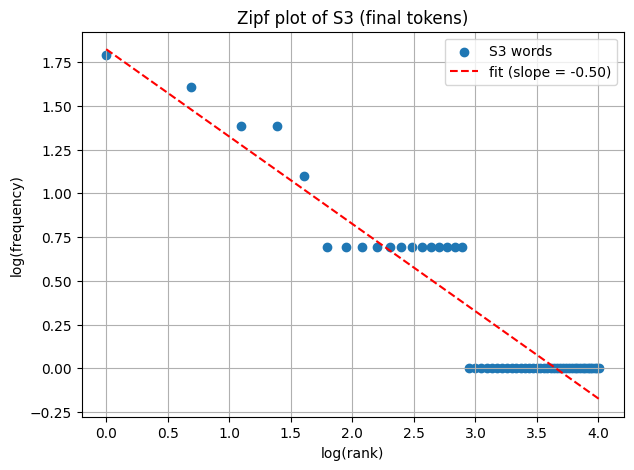


Top 5 bigrams of S1:
  ('.', 'it')  4
  ('it', 'works')  4
  ('works', 'on')  4
  ('on', 'another')  4
  ('another', 'computer')  4

Top 5 bigrams of S3:
  ('works', 'another')  4
  ('another', 'computer')  4
  ("n't", 'know')  2
  ('know', 'changed')  2
  ('another', 'solution')  2


In [17]:
S1 = [w for p in processed.values() for w in p["tokens"]]        # all tokens
S2 = [w for w in S1 if not is_punct(w)]                           # without punctuation
S3 = [w for p in processed.values() for w in p["final"]]         # final tokens
S4 = [porter.stem(w) for w in S3]                                 # S3 after Porter stemming

stats = []
for name, S in [("S1 (all tokens)", S1), ("S2 (no punctuation)", S2),
                ("S3 (final tokens)", S3), ("S4 (S3 + Porter)", S4)]:
    stats.append({"Set": name, "Total Tokens": len(S), "Unique Tokens": len(set(S)),
                  "TTR": round(len(set(S)) / len(S), 4)})
stats_df = pd.DataFrame(stats)
display(stats_df)

# ---- top 10 words ----
for name, S in [("S1", S1), ("S3", S3)]:
    print(f"\nTop 10 words of {name}:")
    for w, c in Counter(S).most_common(10):
        print(f"  {w!r:16} {c}")

# ---- log(rank) vs log(frequency) for S3 ----
freqs = sorted(Counter(S3).values(), reverse=True)
log_rank = np.log(np.arange(1, len(freqs) + 1))
log_freq = np.log(freqs)
slope, intercept = np.polyfit(log_rank, log_freq, 1)

plt.figure(figsize=(7, 5))
plt.scatter(log_rank, log_freq, label="S3 words")
plt.plot(log_rank, slope * log_rank + intercept, "r--", label=f"fit (slope = {slope:.2f})")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot of S3 (final tokens)")
plt.legend()
plt.grid(True)
plt.show()

# ---- top 5 bigrams (built inside each ticket, so no bigram crosses two tickets) ----
def top_bigrams(token_lists, n=5):
    c = Counter()
    for toks in token_lists:
        c.update(bigrams(toks))
    return c.most_common(n)

for name, key in [("S1", "tokens"), ("S3", "final")]:
    print(f"\nTop 5 bigrams of {name}:")
    for bg, c in top_bigrams([p[key] for p in processed.values()]):
        print(f"  {bg}  {c}")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR = unique tokens / total tokens, so it changes whenever a step removes many repeated tokens or merges different forms. Removing punctuation (S1 -> S2) and stopwords (S2 -> S3) deletes the most frequently repeated tokens (`.`, `,`, `the`, `is`, ...), which lowers the total much more than the unique count, so TTR rises. Porter stemming (S3 -> S4) keeps the total but merges inflected forms into one stem, so the unique count drops and TTR falls. The cell below shows the actual numbers.

In [18]:

ttr = {row["Set"][:2]: row["TTR"] for row in stats}

def trend(a, b):
    return "rises" if ttr[b] > ttr[a] else "falls" if ttr[b] < ttr[a] else "stays the same"

print("TTR:", ttr, "\n")
print(f"S1 -> S2: TTR {trend('S1', 'S2')} ({ttr['S1']} -> {ttr['S2']}): punctuation marks are very repetitive.")
print(f"S2 -> S3: TTR {trend('S2', 'S3')} ({ttr['S2']} -> {ttr['S3']}): stopwords are the most repeated words.")
print(f"S3 -> S4: TTR {trend('S3', 'S4')} ({ttr['S3']} -> {ttr['S4']}): stemming merges variants, so there are fewer unique types.")


TTR: {'S1': 0.5, 'S2': 0.5556, 'S3': 0.6471, 'S4': 0.6235} 

S1 -> S2: TTR rises (0.5 -> 0.5556): punctuation marks are very repetitive.
S2 -> S3: TTR rises (0.5556 -> 0.6471): stopwords are the most repeated words.
S3 -> S4: TTR falls (0.6471 -> 0.6235): stemming merges variants, so there are fewer unique types.



---
## Q6. Interpretation
Answer briefly (the examples below are picked from this dataset by the code).



**(a) Why does TTR change from S1 to S4 in your dataset?**

TTR rises from S1 to S2 to S3 because punctuation and stopwords are the most repeated tokens: removing them shrinks the total much more than the number of unique words. It then falls from S3 to S4 because Porter stemming merges inflected forms (e.g. `failed`/`fails`/`failing` -> `fail`), lowering the unique count while the total stays the same. The numbers are printed in the cell after Q5.



**(b) Give one example where `word_tokenize()` and your tokenizer differ.**


In [19]:

why = {
    "email": "word_tokenize() splits the address at '@'; my_tokenize() has an email alternative and keeps it whole.",
    "URL": "word_tokenize() splits at ':' and '//'; my_tokenize() matches the whole URL as one token.",
    "phone number": "word_tokenize() breaks the number at spaces or the '+'; my_tokenize() keeps the phone number whole.",
    "hex / number": "my_tokenize() has a dedicated alternative for hex codes and thousands separators.",
    "version / decimal": "my_tokenize() has a dedicated number alternative, so the dotted number is not split.",
    "abbreviation": "my_tokenize() keeps letter-dot abbreviations such as p.m. together.",
    "contraction": "word_tokenize() follows Penn Treebank and splits the clitic (stem + n't); my_tokenize() keeps the contraction as one word.",
    "hyphenated word": "my_tokenize() allows '-' inside a word, so the compound is kept as a single token.",
    "ellipsis": "my_tokenize() keeps '...' as one token.",
    "merged word": "word_tokenize() splits 'cannot' into 'can' + 'not'; my_tokenize() treats it as a single word.",
    "other": "the two tokenizers apply different rules to this sequence.",
}

# prefer a contraction / email / URL / phone example, because they are the clearest differences
order = ["contraction", "email", "URL", "phone number"]
own = diff_table[diff_table["Found in"] != "TEST_LINES"]
pool = own if len(own) else diff_table
ex = next((pool[pool["Category"] == c].iloc[0] for c in order if (pool["Category"] == c).any()), pool.iloc[0])

print("Found in        :", ex["Found in"])
print("Token           :", ex["my_tokenize"])
print("my_tokenize()   :", [ex["my_tokenize"]])
print("word_tokenize() :", ex["word_tokenize"])
print("Explanation     :", why[ex["Category"]])


Found in        : T01
Token           : don't
my_tokenize()   : ["don't"]
word_tokenize() : ['do', "n't"]
Explanation     : word_tokenize() follows Penn Treebank and splits the clitic (stem + n't); my_tokenize() keeps the contraction as one word.



**(c) Give one example where stemming produces an undesirable result.**


In [20]:

bad = []
for _, r in stem_df.iterrows():
    for name in ["Porter", "Lancaster"]:
        s = r[name]
        if r["Word"].isalpha() and s != r["Word"] and not wordnet.synsets(s):
            bad.append((len(r["Word"]) - len(s), r["Word"], name, s))
bad.sort(reverse=True)

cut, w, name, s = bad[0]
print(f"{name} maps '{w}' -> '{s}'.")
print(f"The stem is not a real word and {cut} letters were removed, so the result is hard to read and the meaning of "
      f"'{w}' is lost. Stemmers only chop suffixes by rule; they do not know the dictionary form.")
print("\nOther examples:", [(w2, n2, s2) for _, w2, n2, s2 in bad[1:6]])


Lancaster maps 'solution' -> 'solv'.
The stem is not a real word and 4 letters were removed, so the result is hard to read and the meaning of 'solution' is lost. Stemmers only chop suffixes by rule; they do not know the dictionary form.

Other examples: [('solution', 'Porter', 'solut'), ('nothing', 'Porter', 'noth'), ('nothing', 'Lancaster', 'noth'), ('tried', 'Porter', 'tri'), ('tried', 'Lancaster', 'tri')]



**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**


In [21]:

cands = []
for w in [x for x in unique_final if x.isalpha()]:
    tag = get_tag(w)
    lem_pos = lemmatizer.lemmatize(w, to_wn_pos(tag))
    lem_noun = lemmatizer.lemmatize(w)              # default POS = noun
    stem = porter.stem(w)
    if lem_pos != stem and wordnet.synsets(lem_pos):
        cands.append((w, tag, lem_pos, lem_noun, stem))

# prefer words whose Porter stem is not a real word and where POS information changes the lemma
cands.sort(key=lambda c: (bool(wordnet.synsets(c[4])), c[2] == c[3], c[2] == c[0]))
w, tag, lem_pos, lem_noun, stem = cands[0]

print(f"Word: '{w}'  (POS tag: {tag})")
print(f"  Porter stem            : {stem}")
print(f"  Lemma without POS info : {lem_noun}")
print(f"  Lemma with POS info    : {lem_pos}")
print("The POS-aware lemma is a valid dictionary word of the right grammatical category, "
      "while the stem is only a truncated form that is often not a word.")


Word: 'replied'  (POS tag: VBN)
  Porter stem            : repli
  Lemma without POS info : replied
  Lemma with POS info    : reply
The POS-aware lemma is a valid dictionary word of the right grammatical category, while the stem is only a truncated form that is often not a word.
